# Pilot data preview and baseline models
In this notebook I examined the data from GSE84133 dataset (human pancreas) as our Dataset A. I inspect the dataset here, handle missing values, make comparable subsets, preprocess the dataset with log(x+1) normalization, perform the E1 with SVM and E2 by freezing it and train on all A and perform the test on all B (second dataset). Then repeat the came but with PCA and k-NN.

In [1]:
from pathlib import Path
import GEOparse

soft_path  = Path("/home/professor/Downloads/proj_data/GSE84133_family.soft")
gse = GEOparse.get_GEO(filepath=str(soft_path))

print("GEO accession:", gse.name)
print("Number of samples:", len(gse.gsms))
print("First sample IDs:", list(gse.gsms.keys())[:5])

/home/professor/miniconda3/envs/dataenv/lib/python3.12/site-packages/pandas/core/computation/expressions.py:23: UserWarning: Pandas requires version '2.10.2' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import NUMEXPR_INSTALLED
22-Oct-2026 13:09:45 INFO GEOparse - Parsing /home/professor/Downloads/proj_data/GSE84133_family.soft: 


22-Oct-2026 13:09:45 DEBUG GEOparse - DATABASE: GeoMiame


22-Oct-2026 13:09:45 DEBUG GEOparse - SERIES: GSE84133


22-Oct-2026 13:09:45 DEBUG GEOparse - PLATFORM: GPL16791


22-Oct-2026 13:09:45 DEBUG GEOparse - PLATFORM: GPL17021


...

22-Oct-2026 13:09:46 DEBUG GEOparse - SAMPLE: GSM2230759


22-Oct-2026 13:09:46 DEBUG GEOparse - SAMPLE: GSM2230760


22-Oct-2026 13:09:46 DEBUG GEOparse - SAMPLE: GSM2230761


22-Oct-2026 13:09:46 DEBUG GEOparse - SAMPLE: GSM2230762


GEO accession: GSE84133
Number of samples: 6
First sample IDs: ['GSM2230757', 'GSM2230758', 'GSM2230759', 'GSM2230760', 'GSM2230761']


In [2]:
gsm_id = next(iter(gse.gsms))
gsm = gse.gsms[gsm_id]

print("Sample:", gsm_id)
print(gsm.metadata.keys())
print(gsm.table.head())
print(gsm.table.shape)

Sample: GSM2230757
dict_keys(['title', 'geo_accession', 'status', 'submission_date', 'last_update_date', 'type', 'channel_count', 'source_name_ch1', 'organism_ch1', 'taxid_ch1', 'characteristics_ch1', 'treatment_protocol_ch1', 'molecule_ch1', 'extract_protocol_ch1', 'data_processing', 'platform_id', 'contact_name', 'contact_institute', 'contact_address', 'contact_city', 'contact_state', 'contact_zip/postal_code', 'contact_country', 'instrument_model', 'library_selection', 'library_source', 'library_strategy', 'relation', 'supplementary_file_1', 'series_id', 'data_row_count'])
Empty DataFrame
Columns: []
Index: []
(0, 0)


**Why is the GEO table empty?** GEO SOFT files carry only *metadata* for sequencing series. For array data the
expression values live in the sample tables, but for scRNA-seq the count matrices are deposited as **supplementary
files** (`GSM..._human1_umifm_counts.csv.gz` etc., see the `supplementary_file_1` key above). So `gsm.table` is
legitimately `(0, 0)`. The SOFT parse is still useful to confirm the series layout: **6 samples = 4 human donors +
2 mouse strains** (GPL16791 = human HiSeq 2500, GPL17021 = mouse HiSeq 2500).

Instead of re-assembling the supplementary CSVs, we use the curated `baron-human.rds` object from the Hemberg-lab
scRNA-seq dataset collection (the file inside `sRNA sequencing - Pancreas (GSE84133).zip`). It contains the same
UMI counts for the **human** part of GSE84133 plus the authors' cell-type labels. The mouse part is not in it.

---
# Part 1 — Dataset inspection
Goal: understand *what* is in the data and *how it behaves* before deciding on any preprocessing. Nothing in this part
changes the data that later goes into the models; the quick normalisation used for the PCA overview (§1.8) is for
looking only.

## 1.0 Conversion from R and setup
The `.rds` files are R `SingleCellExperiment` (S4) objects, which Python cannot read directly (`pyreadr` only handles
data frames). We convert them once with two small scripts that live in `scripts/`:

1. `Rscript scripts/export_sce.R <in.rds> <out_dir>` writes every assay as a sparse MatrixMarket file plus `obs.csv`
   (cell metadata) and `var.csv` (gene metadata). It refuses to write if names are duplicated or the matrix has NAs.
2. `python -I scripts/build_h5ad.py <out_dir> <out.h5ad>` transposes to **cells × genes** (the sklearn convention:
   one row per sample) and saves an `.h5ad`. Raw counts become `X` when available; all assays are kept as layers.

The archives were unzipped into `data/raw/<dataset>/`, the converted files are in `data/interim/`. `data/` is
git-ignored, since raw data should come from the public accessions and not from the repository.

In [3]:
# --- Imports ---------------------------------------------------------------
import warnings
warnings.filterwarnings("ignore", category=UserWarning)   # silence pandas/numexpr version chatter

from pathlib import Path
import numpy as np
import pandas as pd
import scipy.sparse as sp
import anndata as ad
import scanpy as sc
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

# --- Reproducibility ------------------------------------------------------------
# The proposal requires every stochastic step to be seeded. PCA (randomised solver)
# and silhouette subsampling below are the only random steps in this part.
SEED = 0
np.random.seed(SEED)

# --- Paths ------------------------------------------------------------------
PROJECT  = Path("/home/professor/cell-type-annotaion-benchmark")
INTERIM  = PROJECT / "data" / "interim"
BARON_H5 = INTERIM / "baron_human.h5ad"
CAMP_H5  = INTERIM / "camp_brain.h5ad"
for p in (BARON_H5, CAMP_H5):
    assert p.exists(), f"{p} missing: run scripts/export_sce.R and scripts/build_h5ad.py first (see 1.0)"

# --- Plot style -----------------------------------------------------------------
# Recessive axes/grid, thin marks. Categorical colours are taken in a fixed order
# from a colour-blind-validated palette and are tied to an entity (donor, lineage),
# never to rank, so the same donor has the same colour in every figure.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "legend.frameon": False,
})
from importlib.metadata import version
print("scanpy", version("scanpy"), "| anndata", version("anndata"), "| scikit-learn", version("scikit-learn"))

scanpy 1.12.4 | anndata 0.13.4 | scikit-learn 1.7.1


## 1.1 Overview of the Baron (GSE84133, human) object

In [4]:
baron = ad.read_h5ad(BARON_H5)
print(baron)
print("\nX is assay:", baron.uns["X_source_assay"], "| dtype:", baron.X.dtype, "| sparse:", sp.issparse(baron.X))
print(f"Sparsity (fraction of zeros): {1 - baron.X.nnz / np.prod(baron.shape):.3f}")
baron.obs.iloc[:3, :6]

AnnData object with n_obs × n_vars = 8569 × 20125
    obs: 'human', 'cell_type1', 'total_features', 'log10_total_features', 'total_counts', 'log10_total_counts', 'pct_counts_top_50_features', 'pct_counts_top_100_features', 'pct_counts_top_200_features', 'pct_counts_top_500_features', 'total_features_endogenous', 'log10_total_features_endogenous', 'total_counts_endogenous', 'log10_total_counts_endogenous', 'pct_counts_endogenous', 'pct_counts_top_50_features_endogenous', 'pct_counts_top_100_features_endogenous', 'pct_counts_top_200_features_endogenous', 'pct_counts_top_500_features_endogenous', 'total_features_feature_control', 'log10_total_features_feature_control', 'total_counts_feature_control', 'log10_total_counts_feature_control', 'pct_counts_feature_control', 'total_features_ERCC', 'log10_total_features_ERCC', 'total_counts_ERCC', 'log10_total_counts_ERCC', 'pct_counts_ERCC', 'is_cell_control'
    var: 'feature_symbol', 'is_feature_control', 'is_feature_control_ERCC', 'mean_counts

,human,cell_type1,total_features,log10_total_features,total_counts,log10_total_counts
cell_id,,,,,,
human1_lib1.final_cell_0001,1,acinar,3526,3.547405,22412,4.350500
human1_lib1.final_cell_0002,1,acinar,4201,3.623456,27953,4.446444
human1_lib1.final_cell_0003,1,acinar,2119,3.326336,16895,4.227784


**What we have:** 8,569 cells × 20,125 genes, two assays:

* `counts`: raw UMI counts (inDrop, 3'-end, UMI-deduplicated). These are what the proposal's preprocessing
  ("library-size normalisation followed by log(1+x)") must start from.
* `logcounts`: a normalised version made by the curators with *scater* (log2 of size-factor-normalised counts + 1).
  We **do not** use it as model input. It was computed on all cells together, so if a reference/query split
  comes later it would leak information between the two; it also uses log2 rather than the natural log.

About 91% of entries are zero, which is typical of droplet data and is why everything stays in sparse (CSR) format.

`obs` has 30 columns. Only two carry biological meaning: `human` (donor 1–4) and `cell_type1` (author label). The
other 28 are QC statistics pre-computed by `scater` (total counts, detected genes, % in top-N genes, ERCC/control
metrics). They are checked in the next cell.

**Where the expression values live.** `baron` is an AnnData object: three linked parts, of which only two are tables
that get printed. `baron.X` is the expression matrix itself, one row per cell and one column per gene (for Baron: raw UMI counts). It is
stored *sparse* (only the non-zero entries and their positions) because most entries are zero, so it is never shown as
a table. `baron.obs` is one row per cell (labels, donor, QC: the table above), and `baron.var` is one row per gene: its index,
`baron.var_names`, holds the gene names, i.e. the column names of `X`. Neither contains expression values. `baron.layers`
holds other versions of the same matrix (`counts`, identical to `X`, and the curators' `logcounts`). The expression of a gene in a cell is read by slicing `X` with cell
IDs and gene names; below, one example cell per major type against the marker gene of each type.

In [ ]:
# Where the expression values live: baron.X is the cells x genes matrix; its rows are named by baron.obs_names (cells)
# and its columns by baron.var_names (genes). baron.obs / baron.var describe those rows / columns and hold no expression.
print("X:", type(baron.X).__name__, baron.X.shape, "| holds:", baron.uns["X_source_assay"],
      "| other versions in layers:", [k for k in baron.layers.keys() if k is not None])   # None = X itself in this anndata
print("Gene names = column names of X (var_names):", list(baron.var_names[:5]), "...")
print(f"Stored non-zero values: {baron.X.nnz:,} of {np.prod(baron.shape):,} entries")

# A small window into X: one example cell per type (rows) x the marker gene of each type (columns).
ex_types = ['alpha', 'beta', 'delta', 'gamma', 'acinar', 'ductal']
ex_genes = ['GCG', 'INS', 'SST', 'PPY', 'PRSS1', 'KRT19']
ex_cells = [baron.obs_names[baron.obs["cell_type1"] == t][0] for t in ex_types]
ex_window = baron[ex_cells, ex_genes].to_df()
ex_window.insert(0, "cell_type1", baron.obs.loc[ex_cells, "cell_type1"].values)
ex_window

X: csr_matrix (8569, 20125) | holds: counts | other versions in layers: ['counts', 'logcounts']
Gene names = column names of X (var_names): ['A1BG', 'A1CF', 'A2M', 'A2ML1', 'A4GALT'] ...
Stored non-zero values: 16,171,764 of 172,451,125 entries


gene_id,cell_type1,GCG,INS,SST,PPY,PRSS1,KRT19
cell_id,,,,,,,
human1_lib1.final_cell_0022,alpha,494.0,119.0,24.0,1.0,0.0,0.0
human1_lib1.final_cell_0007,beta,4.0,3067.0,50.0,2.0,0.0,0.0
human1_lib1.final_cell_0013,delta,0.0,22.0,3108.0,0.0,0.0,0.0
human1_lib1.final_cell_0163,gamma,1.0,22.0,17.0,1364.0,0.0,1.0
human1_lib1.final_cell_0001,acinar,1.0,29.0,32.0,4.0,498.0,0.0
human1_lib1.final_cell_0019,ductal,2.0,13.0,17.0,0.0,0.0,46.0


## 1.2 Data integrity and missing values
The pilot plan says "handle missing values". In a count matrix "missing" can mean several things, so each one is
checked explicitly:
1. NaN/Inf in the matrix or the metadata, i.e. genuinely missing values;
2. negative or non-integer counts, which would mean the "raw" counts are not actually raw;
3. duplicated cell or gene names, which make indices ambiguous;
4. constant metadata columns, which carry no information;
5. genes never detected, which are not missing values but are dead features.

In [ ]:
X = baron.X
obs = baron.obs

checks = {
    "NaN/Inf in counts":            int((~np.isfinite(X.data)).sum()),
    "negative counts":              int((X.data < 0).sum()),
    "non-integer counts":           int((X.data != np.round(X.data)).sum()),
    "NaN cells in obs":             int(obs.isna().sum().sum()),
    "NaN cells in var":             int(baron.var.isna().sum().sum()),
    "duplicated cell IDs":          int(baron.obs_names.duplicated().sum()),
    "duplicated gene names":        int(baron.var_names.duplicated().sum()),
    "cells with zero counts":       int((np.asarray(X.sum(1)).ravel() == 0).sum()),
    "genes detected in 0 cells":    int((np.asarray((X > 0).sum(0)).ravel() == 0).sum()),
}
display(pd.Series(checks, name="count").to_frame())

# Does the stored total_counts match the matrix? (verifies the R->Python conversion)
lib = np.asarray(X.sum(1)).ravel()
assert np.allclose(lib, obs["total_counts"]), "conversion mismatch"
print("obs.total_counts matches row sums of X -> conversion is lossless")

constant_cols = [c for c in obs.columns if obs[c].nunique() == 1]
print(f"\n{len(constant_cols)} constant obs columns (no information):", constant_cols)

,count
NaN/Inf in counts,0
negative counts,0
non-integer counts,0
NaN cells in obs,0
NaN cells in var,0
duplicated cell IDs,0
duplicated gene names,0
cells with zero counts,0
genes detected in 0 cells,2626


obs.total_counts matches row sums of X -> conversion is lossless

12 constant obs columns (no information): ['pct_counts_endogenous', 'total_features_feature_control', 'log10_total_features_feature_control', 'total_counts_feature_control', 'log10_total_counts_feature_control', 'pct_counts_feature_control', 'total_features_ERCC', 'log10_total_features_ERCC', 'total_counts_ERCC', 'log10_total_counts_ERCC', 'pct_counts_ERCC', 'is_cell_control']


In [6]:
# Gene-name hygiene: mitochondrial / ribosomal / spike-in / odd names.
names = baron.var_names.to_series()
print("MT- genes:              ", names.str.startswith("MT-").sum())
print("RPL/RPS ribosomal genes:", names.str.match(r"^RP[LS]\d").sum())
print("names starting 'ERCC':  ", list(names[names.str.startswith("ERCC")][:8]), "<- real DNA-repair genes, not spike-ins")
print("lower-case names:       ", list(names[names.str.match(r"^[a-z]")]))

MT- genes:               0
RPL/RPS ribosomal genes: 104
names starting 'ERCC':   ['ERCC1', 'ERCC2', 'ERCC3', 'ERCC4', 'ERCC5', 'ERCC6', 'ERCC6.PGBD3', 'ERCC6L'] <- real DNA-repair genes, not spike-ins
lower-case names:        ['pk']


**Integrity results**
* **There are no missing values anywhere.** No NaN in the matrix or metadata, no negative or fractional counts, no
  duplicated identifiers, no empty cells. For this dataset "handling missing values" therefore comes down to
  (a) dropping the 12 constant QC columns (all ERCC/feature-control metrics are 0 because inDrop has no spike-ins)
  and (b) dealing with **2,626 genes that are never detected**. Those are not missing data. They are features
  that are zero everywhere, carry no information and would only slow the models down.
* The `ERCC1…ERCC8` names are real human genes (excision repair), not spike-in controls, so they must not be
  removed by an `ERCC` prefix filter.
* One gene is called `pk`, an annotation artifact from the original CSV. It is harmless but is noted for the
  gene-intersection step.
* **No mitochondrial (`MT-`) genes are present.** The authors removed them. The standard "% mitochondrial reads"
  QC filter therefore **cannot be applied** to this dataset. This matters for the shared-QC rule in the proposal
  (§IV-E): an MT-based filter cannot be part of the common QC across the pancreas datasets.

## 1.3 Cell-type labels: what are we classifying?

In [7]:
ct = obs["cell_type1"].astype(str)
donor = obs["human"].astype(str).radd("donor ")
counts_tbl = ct.value_counts()
summary = pd.DataFrame({"n_cells": counts_tbl, "fraction_%": (100 * counts_tbl / counts_tbl.sum()).round(2)})
display(summary)
print(f"{ct.nunique()} classes; imbalance ratio largest/smallest = {counts_tbl.max() / counts_tbl.min():.0f}x")

xt = pd.crosstab(ct, donor)
xt = xt.loc[counts_tbl.index]
display(xt.style.background_gradient(cmap="Blues", axis=None))

,n_cells,fraction_%
cell_type1,,
beta,2525,29.47
alpha,2326,27.14
ductal,1077,12.57
acinar,958,11.18
delta,601,7.01
activated_stellate,284,3.31
gamma,255,2.98
endothelial,252,2.94
quiescent_stellate,173,2.02


14 classes; imbalance ratio largest/smallest = 361x


human,donor 1,donor 2,donor 3,donor 4
cell_type1,,,,
beta,872,371,787,495
alpha,236,676,1130,284
ductal,120,301,376,280
acinar,110,3,843,2
delta,214,125,161,101
activated_stellate,51,81,100,52
gamma,70,86,36,63
endothelial,130,23,92,7
quiescent_stellate,92,22,54,5


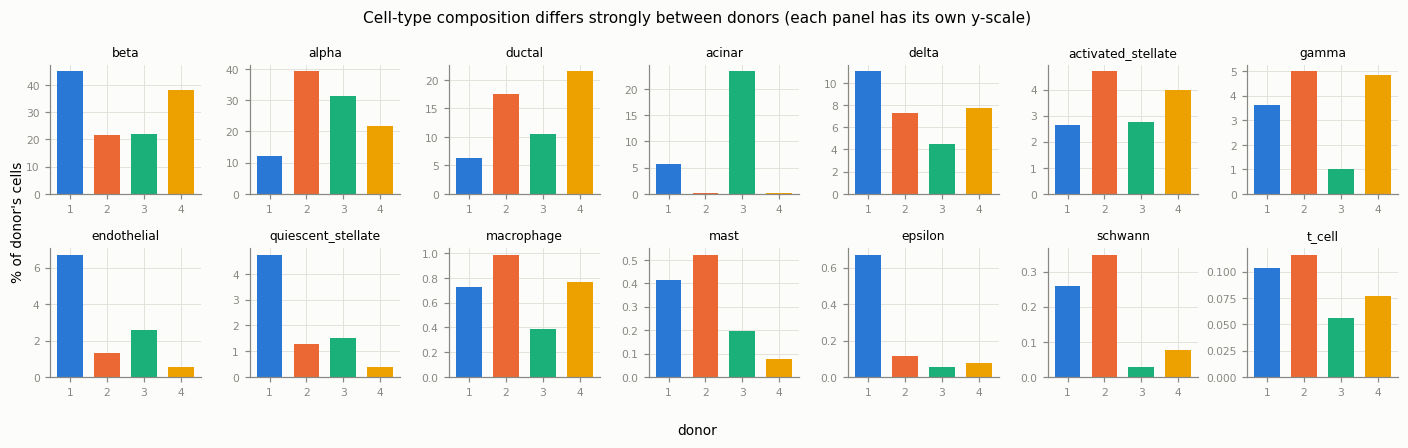

In [8]:
# Cell-type composition per donor (fractions), to see whether donors are interchangeable.
# One horizontal stacked bar per donor would hide the small classes; small multiples per class keep them visible.
frac = xt.div(xt.sum(axis=0), axis=1) * 100
fig, axes = plt.subplots(2, 7, figsize=(13, 4), sharey=False)
for ax, t in zip(axes.ravel(), frac.index):
    ax.bar(range(4), frac.loc[t].values, color=PALETTE[:4], width=0.7)
    ax.set_title(t, fontsize=8)
    ax.set_xticks(range(4), ["1", "2", "3", "4"])
    ax.tick_params(labelsize=7)
fig.supxlabel("donor", fontsize=9)
fig.supylabel("% of donor's cells", fontsize=9)
fig.suptitle("Cell-type composition differs strongly between donors (each panel has its own y-scale)", fontsize=10)
fig.tight_layout()
plt.show()

**Label observations**
* **14 classes, heavily imbalanced (361×).** Beta (2,525) and alpha (2,326) make up 57% of cells, while t_cell (7),
  schwann (13), epsilon (18) and mast (25) are tiny. Accuracy would be dominated by alpha and beta, which is why the
  proposal uses **macro-F1**. The rare classes are also the natural material for **E4 (rare populations)**.
* **Classes this small break stratified 5-fold CV (E1).** With 7 T cells, each fold holds 1–2 test cells, so their
  per-class F1 jumps between 0 and 1. A minimum class size (see the strategy in Part 2) is needed for the F1 average
  to be stable.
* **Donor composition is far from uniform.** 843 of the 958 acinar cells (88%) come from **donor 3**, and donors 2
  and 4 have only 3 and 2 acinar cells. Donor 1 has most of the endothelial and quiescent stellate cells. A
  donor-wise split therefore also changes the *class prior*, not just the expression. This is the "cell-type
  composition" shift named in the research question.
* **The labels form a natural hierarchy:** endocrine (alpha, beta, delta, gamma/PP, epsilon), exocrine (acinar,
  ductal), stromal/mesenchymal (activated and quiescent stellate, endothelial, schwann) and immune (macrophage, mast,
  T cell). This is the top of the Cell Ontology subgraph that the HOE metric will need, and it is used for colouring
  below. Note that `activated_stellate` and `quiescent_stellate` are **states of one cell type**, so confusing them
  should cost less than confusing alpha with acinar. That is exactly the point of HOE.

## 1.4 Per-cell quality metrics: library size and detected genes

In [9]:
LINEAGE = {
    "alpha": "endocrine", "beta": "endocrine", "delta": "endocrine", "gamma": "endocrine", "epsilon": "endocrine",
    "acinar": "exocrine", "ductal": "exocrine",
    "activated_stellate": "stromal", "quiescent_stellate": "stromal", "endothelial": "stromal", "schwann": "stromal",
    "macrophage": "immune", "mast": "immune", "t_cell": "immune",
}
LINEAGE_ORDER = ["endocrine", "exocrine", "stromal", "immune"]
LINEAGE_COLOR = dict(zip(LINEAGE_ORDER, PALETTE[:4]))
DONOR_COLOR = {f"donor {i}": PALETTE[i - 1] for i in range(1, 5)}

qc = pd.DataFrame({
    "total_counts": lib,
    "n_genes": np.asarray((X > 0).sum(1)).ravel(),
    "top_gene_frac": np.asarray(X.max(1).todense()).ravel() / lib,   # share of the cell's UMIs in its single top gene
    "cell_type": ct.values, "donor": donor.values,
}, index=baron.obs_names)
qc["lineage"] = qc["cell_type"].map(LINEAGE)
display(qc[["total_counts", "n_genes", "top_gene_frac"]].describe().round(3).T)

,count,mean,std,min,25%,50%,75%,max
total_counts,8569.0,5828.226,3418.385,1201.000,3636.000,5075.0,7011.000,34509.000
n_genes,8569.0,1887.241,620.413,767.000,1437.000,1847.0,2259.000,4922.000
top_gene_frac,8569.0,0.127,0.104,0.006,0.047,0.1,0.185,0.616


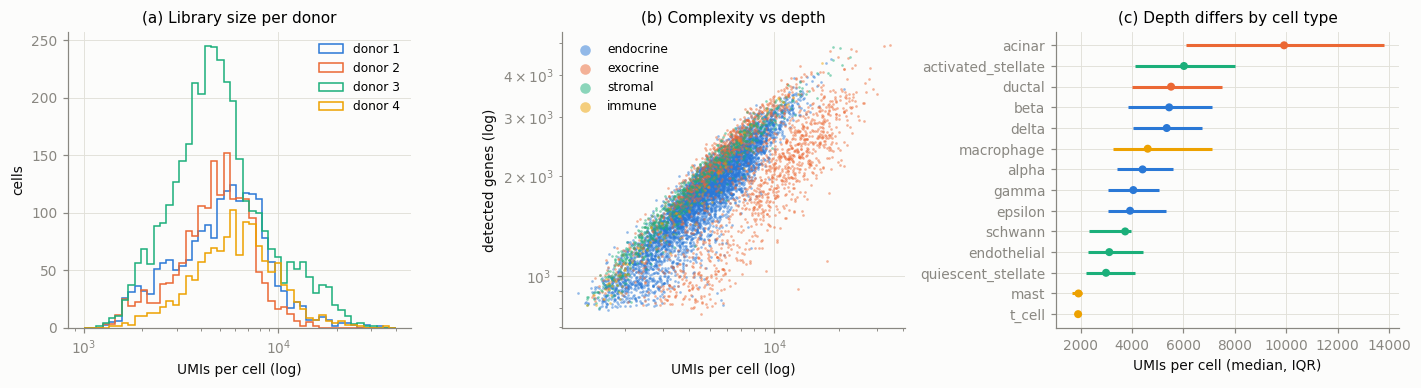

Minimum UMIs / genes in any cell: 1201 / 767
Median top-gene fraction by type:
 cell_type
delta                 0.349
beta                  0.178
gamma                 0.152
epsilon               0.117
alpha                 0.097
acinar                0.072
macrophage            0.042
activated_stellate    0.029
schwann               0.021
mast                  0.020
t_cell                0.019
quiescent_stellate    0.018
ductal                0.017
endothelial           0.012


In [10]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))

# (a) library-size distribution per donor (log x-axis: counts are right-skewed)
bins = np.logspace(np.log10(1000), np.log10(40000), 50)
for d, c in DONOR_COLOR.items():
    axes[0].hist(qc.loc[qc.donor == d, "total_counts"], bins=bins, histtype="step", lw=1.5, color=c, label=d)
axes[0].set_xscale("log"); axes[0].set_xlabel("UMIs per cell (log)"); axes[0].set_ylabel("cells")
axes[0].set_title("(a) Library size per donor"); axes[0].legend(fontsize=8)

# (b) detected genes vs UMIs, coloured by lineage
for l in LINEAGE_ORDER:
    s = qc.lineage == l
    axes[1].scatter(qc.total_counts[s], qc.n_genes[s], s=3, alpha=0.5, color=LINEAGE_COLOR[l], label=l, linewidths=0)
axes[1].set_xscale("log"); axes[1].set_yscale("log")
axes[1].set_xlabel("UMIs per cell (log)"); axes[1].set_ylabel("detected genes (log)")
axes[1].set_title("(b) Complexity vs depth"); axes[1].legend(markerscale=4, fontsize=8)

# (c) library size per cell type (median and IQR), sorted
g = qc.groupby("cell_type")["total_counts"]
order = g.median().sort_values().index
med, q1, q3 = g.median()[order], g.quantile(.25)[order], g.quantile(.75)[order]
y = np.arange(len(order))
axes[2].hlines(y, q1, q3, color=[LINEAGE_COLOR[LINEAGE[t]] for t in order], lw=2)
axes[2].scatter(med, y, color=[LINEAGE_COLOR[LINEAGE[t]] for t in order], s=18, zorder=3)
axes[2].set_yticks(y, order); axes[2].set_xlabel("UMIs per cell (median, IQR)")
axes[2].set_title("(c) Depth differs by cell type")
fig.tight_layout(); plt.show()

print("Minimum UMIs / genes in any cell:", int(qc.total_counts.min()), "/", int(qc.n_genes.min()))
print("Median top-gene fraction by type:\n", qc.groupby("cell_type").top_gene_frac.median().sort_values(ascending=False).round(3).to_string())

**QC observations**
* **The data have already been filtered.** No cell has fewer than 1,201 UMIs or 767 detected genes, and the
  distributions start abruptly at those values in (a). Baron et al. applied their own QC before deposition. A
  standard low-quality filter (e.g. < 200 genes) would remove **nothing**, and inventing a stricter one would only
  remove real cells. The upper tail (up to ~34k UMIs) is consistent with large acinar cells rather than obvious
  doublets.
* **Depth and complexity are tightly coupled** in (b), with no separate low-complexity/low-depth cluster of the
  kind that marks empty droplets or dying cells. The one deviation is a group of **exocrine (acinar) cells below the
  main band**: many UMIs but relatively few genes. That is biology rather than poor quality. Acinar cells spend much
  of their mRNA on a few digestive enzymes (PRSS1/2, CTRB1/2, CELA3A, REG1A), so a "genes per UMI" filter would
  wrongly remove them. This is a further reason not to add stricter QC.
* **Depth is a property of the cell type** (c): acinar cells have about 2× the UMIs of alpha cells and 5× those of
  mast or T cells. This is one reason **library-size normalisation** (dividing each cell by its total) is needed:
  without it a classifier could partly learn "large library → acinar", which is a technical shortcut that would not
  transfer to another protocol.
* **A few hormone genes dominate the endocrine cells.** In a median delta cell, 35% of all UMIs come from one gene
  (SST); in beta cells it is 18% (INS). After per-cell normalisation the remaining genes of such cells are
  compressed, and the log transform (§1.5) is what keeps this from dominating the distance computations.
* Donors differ modestly in depth (median 4.7k–6.0k UMIs). Donor 4 is deepest, which is a mild technical shift
  between donors.

## 1.5 Gene-level behaviour: detection, top genes, mean–variance relationship

In [11]:
n_cells_expr = np.asarray((X > 0).sum(0)).ravel()
gene_tot = np.asarray(X.sum(0)).ravel()
mean = np.asarray(X.mean(0)).ravel()
var = np.asarray(X.multiply(X).mean(0)).ravel() - mean ** 2

thresholds = [0, 2, 9, 19, 49]
print("Genes detected in at most k cells:")
for k in thresholds:
    print(f"  <= {k:>2} cells: {(n_cells_expr <= k).sum():>5}  ({100 * (n_cells_expr <= k).mean():.1f}%)")

top = pd.Series(gene_tot / gene_tot.sum() * 100, index=baron.var_names).sort_values(ascending=False).head(15)
print("\nTop-15 genes by share of all UMIs (%):"); print(top.round(2).to_string())

Genes detected in at most k cells:


  <=  0 cells:  2626  (13.0%)
  <=  2 cells:  3766  (18.7%)
  <=  9 cells:  5008  (24.9%)
  <= 19 cells:  5803  (28.8%)
  <= 49 cells:  7044  (35.0%)

Top-15 genes by share of all UMIs (%):
gene_id
INS       5.34
SST       2.43
GCG       2.41
REG1A     1.56
TTR       1.10
IAPP      0.94
PRSS2     0.87
EEF1A1    0.86
CTRB2     0.76
CELA3A    0.75
CTRB1     0.73
FTL       0.64
RPL41     0.53
ACTG1     0.50
FTH1      0.49


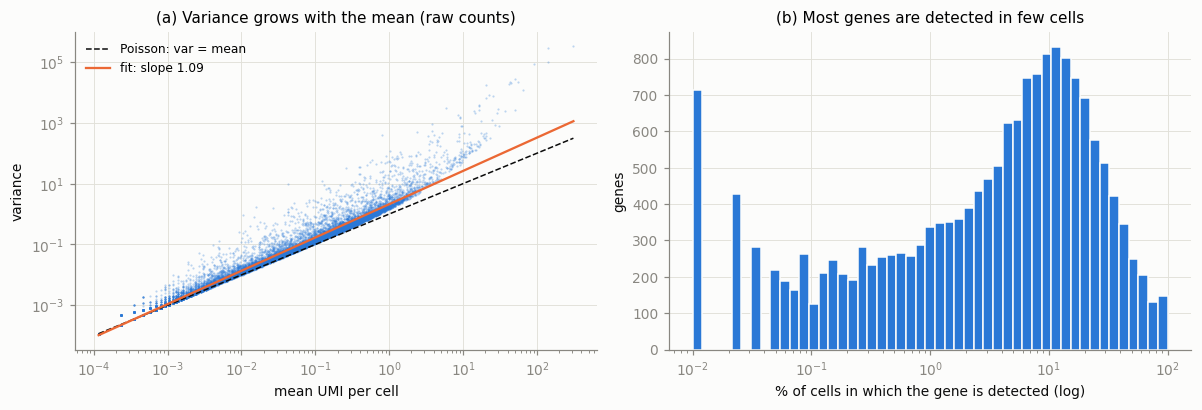

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
k = mean > 0
axes[0].scatter(mean[k], var[k], s=2, alpha=0.3, color=PALETTE[0], linewidths=0)
xx = np.logspace(np.log10(mean[k].min()), np.log10(mean[k].max()), 50)
axes[0].plot(xx, xx, color=INK, lw=1, ls="--", label="Poisson: var = mean")
slope, icpt = np.polyfit(np.log10(mean[k]), np.log10(var[k]), 1)
axes[0].plot(xx, 10 ** icpt * xx ** slope, color=PALETTE[1], lw=1.5, label=f"fit: slope {slope:.2f}")
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("mean UMI per cell"); axes[0].set_ylabel("variance"); axes[0].legend(fontsize=8)
axes[0].set_title("(a) Variance grows with the mean (raw counts)")

det = n_cells_expr / baron.n_obs * 100
axes[1].hist(det[det > 0], bins=np.logspace(np.log10(0.01), 2, 50), color=PALETTE[0], edgecolor="#fcfcfb", lw=0.5)
axes[1].set_xscale("log"); axes[1].set_xlabel("% of cells in which the gene is detected (log)")
axes[1].set_ylabel("genes"); axes[1].set_title("(b) Most genes are detected in few cells")
fig.tight_layout(); plt.show()

**Gene-level observations**
* **Variance scales with the mean (log-log slope ≈ 1.1), and highly expressed genes are overdispersed above the
  Poisson line.** On raw counts, a handful of high-mean genes (INS, SST, GCG, REG1A, digestive enzymes) would
  dominate any Euclidean distance, PCA axis or SVM margin. `log(1 + x)` compresses this (roughly variance-stabilising
  for counts), which is the statistical justification for the transform the proposal prescribes, and it matters for
  both pilot models: the linear SVM's margins and k-NN's Euclidean distances on PCs.
* **The top genes are almost all hormones and digestive enzymes.** INS alone accounts for 5.3% of *all* UMIs in the
  dataset. These genes are very informative but also the main source of the ambient contamination examined next.
* **Feature sparsity:** about 25% of genes are detected in fewer than 10 cells. Such genes cannot help a classifier
  learn a class, and a minimum detection filter (applied on the **reference only**) removes them cheaply.

## 1.6 Ambient RNA: do the labels agree with the markers, and how "clean" are the markers?
For each cell type and a set of canonical marker genes we show the **% of cells with ≥ 1 UMI**. This checks two
things at once: (1) whether the author labels make biological sense, and (2) how specific the markers are in
this technology.

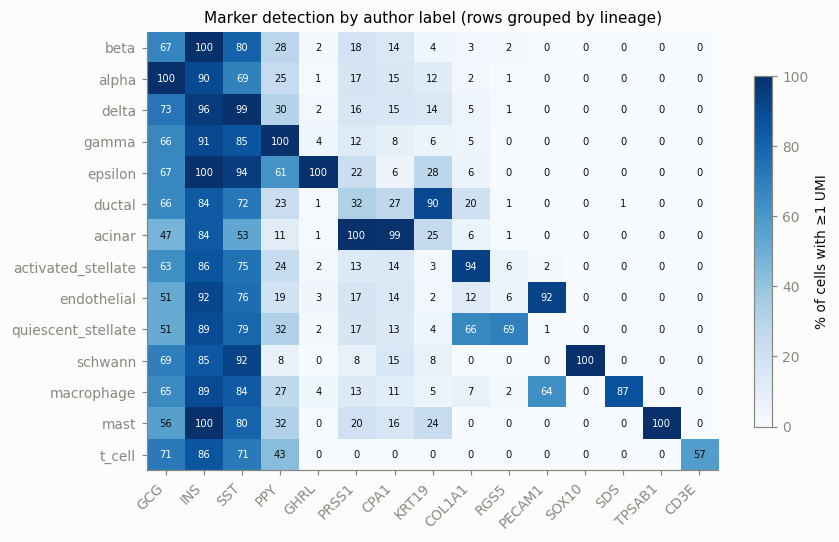

In [13]:
MARKERS = {
    "alpha": "GCG", "beta": "INS", "delta": "SST", "gamma": "PPY", "epsilon": "GHRL",
    "acinar": "PRSS1", "acinar ": "CPA1", "ductal": "KRT19",
    "activated_stellate": "COL1A1", "quiescent_stellate": "RGS5", "endothelial": "PECAM1",
    "schwann": "SOX10", "macrophage": "SDS", "mast": "TPSAB1", "t_cell": "CD3E",
}
genes = list(dict.fromkeys(MARKERS.values()))
type_order = [t for l in LINEAGE_ORDER for t in counts_tbl.index if LINEAGE[t] == l]
detect = pd.DataFrame(
    {g: (np.asarray(X[:, baron.var_names.get_loc(g)].todense()).ravel() > 0) for g in genes},
    index=baron.obs_names).groupby(ct.values).mean().loc[type_order] * 100

fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(detect.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(genes)), genes, rotation=45, ha="right"); ax.set_yticks(range(len(type_order)), type_order)
ax.grid(False)
for i in range(detect.shape[0]):
    for j in range(detect.shape[1]):
        v = detect.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="white" if v > 60 else INK)
fig.colorbar(im, ax=ax, label="% of cells with ≥1 UMI", shrink=0.8)
ax.set_title("Marker detection by author label (rows grouped by lineage)")
fig.tight_layout(); plt.show()

**Marker observations, the most important finding of the inspection**
* **The labels are biologically consistent.** Every type has its marker on the diagonal (TPSAB1 in 100% of mast,
  SOX10 in 100% of Schwann, SDS in 87% of macrophages, GHRL in 100% of epsilon cells, and so on). The author labels
  are good enough to serve as ground truth, with the caveat stated in the proposal that they were derived from the
  same expression data.
* **Strong ambient (cell-free) RNA contamination.** INS is detected in **84–100% of cells of every type**, including
  acinar, endothelial and T cells, and GCG and SST in 50–99%. In inDrop, hormone mRNA released by lysed endocrine
  cells is captured in every droplet. Two consequences for the study:
  1. Hormone genes separate the endocrine types by **level**, not by presence. log1p plus normalisation keeps level
     information, so this is not a problem *within* Baron.
  2. **This is a technology-specific signal.** Smart-seq2 (Segerstolpe) or CEL-Seq2 (Muraro) data have a different
     ambient profile. A model trained on Baron that has learned "low INS = not beta" may meet a query where
     non-beta cells have *zero* INS, or beta cells have saturated INS. This is a concrete mechanism for the
     cross-dataset failures the study is about, and it supports making a "shift descriptor" for E6.
* `PECAM1` is also detected in 64% of macrophages (true biology: macrophages express PECAM1/CD31), and `T cell`
  shows CD3E in only 57% of its 7 cells. T cells are low-depth (median ~1.9k UMIs), so marker dropout is expected.

## 1.7 Global structure: do cells group by type or by donor?
To see whether the labels are separable and how big the donor effect is, we use a **throw-away** version of the
standard pipeline (normalise to 10k → log1p → 2,000 highly variable genes → z-score → PCA) on a copy of the data.
This is for inspection only, and the final preprocessing is decided in Part 2. UMAP is not used: the `umap`
package crashes on import in this environment (segfault via its TensorFlow import), and PCA is what the k-NN
baseline will use anyway.

In [14]:
tmp = baron.copy()
sc.pp.normalize_total(tmp, target_sum=1e4)
sc.pp.log1p(tmp)
sc.pp.highly_variable_genes(tmp, n_top_genes=2000, flavor="seurat")
tmp = tmp[:, tmp.var.highly_variable].copy()
sc.pp.scale(tmp, max_value=10)
sc.tl.pca(tmp, n_comps=50, random_state=SEED)
P = tmp.obsm["X_pca"]
evr = tmp.uns["pca"]["variance_ratio"]
print("Explained variance, PC1..PC10 (%):", np.round(100 * evr[:10], 1))
print(f"Cumulative variance in 20 / 50 PCs: {100 * evr[:20].sum():.1f}% / {100 * evr.sum():.1f}%")

# Silhouette on 20 PCs: +1 = tight separated groups, 0 = overlapping, <0 = mixed.
sil_type = silhouette_score(P[:, :20], ct, sample_size=4000, random_state=SEED)
sil_donor = silhouette_score(P[:, :20], donor, sample_size=4000, random_state=SEED)
print(f"\nSilhouette by cell type: {sil_type:.3f}   by donor: {sil_donor:.3f}")
within = {t: silhouette_score(P[(ct == t).values, :20], donor[(ct == t).values]) for t in ["alpha", "beta", "ductal", "acinar"]}
print("Silhouette by donor *within* one cell type:", {k: round(v, 3) for k, v in within.items()})

Explained variance, PC1..PC10 (%): [7.7 5.1 3.6 3.  2.2 1.5 1.  1.  0.7 0.6]
Cumulative variance in 20 / 50 PCs: 30.3% / 35.9%



Silhouette by cell type: 0.313   by donor: 0.047


Silhouette by donor *within* one cell type: {'alpha': 0.117, 'beta': 0.115, 'ductal': 0.12, 'acinar': 0.165}


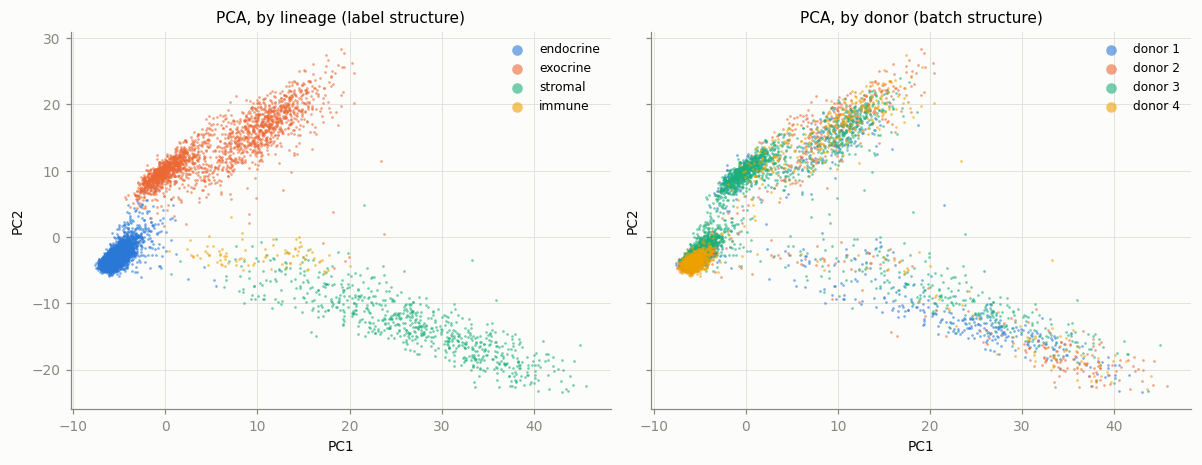

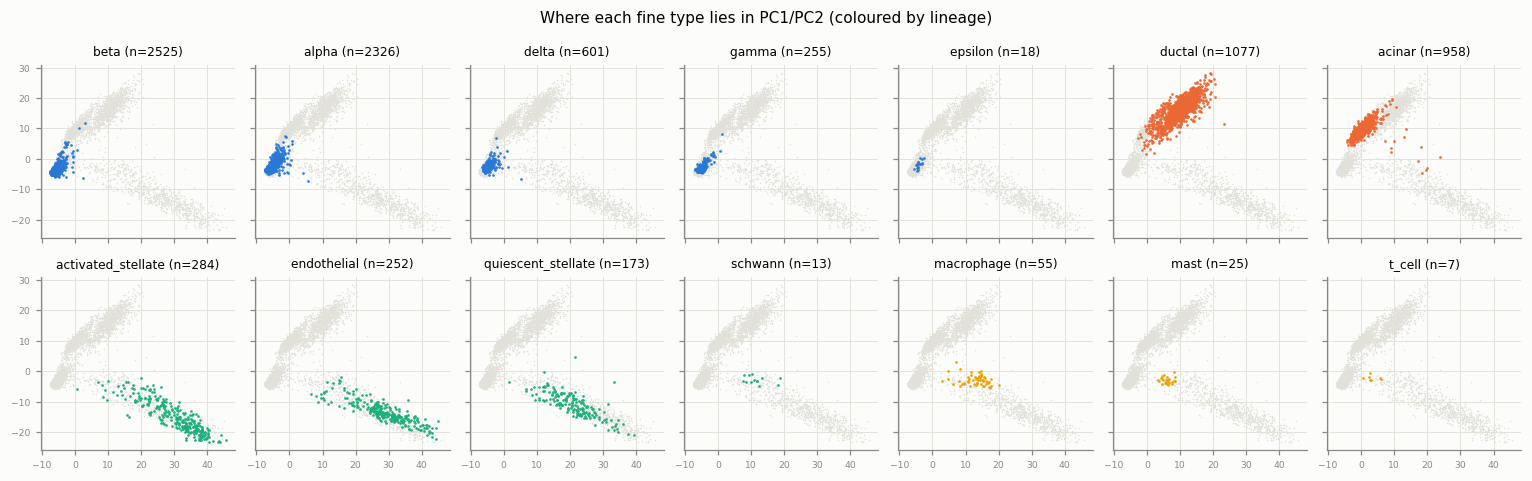

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.3), sharex=True, sharey=True)
rng = np.random.default_rng(SEED)
perm = rng.permutation(baron.n_obs)        # random draw order so no group is always painted on top
lin = qc.lineage.values[perm]; dn = qc.donor.values[perm]; Pp = P[perm]
for l in LINEAGE_ORDER:
    s = lin == l
    axes[0].scatter(Pp[s, 0], Pp[s, 1], s=3, alpha=0.6, color=LINEAGE_COLOR[l], label=l, linewidths=0)
for d in DONOR_COLOR:
    s = dn == d
    axes[1].scatter(Pp[s, 0], Pp[s, 1], s=3, alpha=0.6, color=DONOR_COLOR[d], label=d, linewidths=0)
for ax, t in zip(axes, ["by lineage (label structure)", "by donor (batch structure)"]):
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"PCA, {t}"); ax.legend(markerscale=4, fontsize=8)
fig.tight_layout(); plt.show()

# Fine types: small multiples, each type highlighted over the grey background of all cells.
fig, axes = plt.subplots(2, 7, figsize=(14, 4.4), sharex=True, sharey=True)
for ax, t in zip(axes.ravel(), type_order):
    s = (ct == t).values
    ax.scatter(P[~s, 0], P[~s, 1], s=1, color=GRID, linewidths=0)
    ax.scatter(P[s, 0], P[s, 1], s=3, color=LINEAGE_COLOR[LINEAGE[t]], linewidths=0)
    ax.set_title(f"{t} (n={s.sum()})", fontsize=8); ax.tick_params(labelsize=6)
fig.suptitle("Where each fine type lies in PC1/PC2 (coloured by lineage)", fontsize=10)
fig.tight_layout(); plt.show()

**Structure observations**
* **Cell type dominates the structure** (silhouette 0.31 by type vs 0.05 by donor). The first PCs separate the
  lineages (endocrine vs exocrine vs stromal/immune). Within-dataset classification (E1) should be easy, as expected
  from Abdelaal et al.; the pilot E1 numbers will mostly be a **ceiling** for the transfer experiments.
* **The donor effect is real but second-order.** Within a single type, cells still group somewhat by donor
  (silhouette 0.12–0.17). This is a small-scale version of the shift the study is about: same lab and protocol,
  different person. In the PCA (right panel) it is most visible in the **exocrine arm**, where donor 3 (green) and
  donor 1 (blue) occupy partly different positions. Because donor 3 also holds most acinar cells, label and donor
  are partly **confounded** for acinar, which leave-one-donor-out evaluation will expose.
* **Closely related types overlap in the first two PCs** (alpha/beta/delta/gamma/epsilon, and the two stellate
  states). They separate in higher PCs, which is why the k-NN baseline should use more than a few PCs (about 20–50).
  It also means most within-lineage confusions will be "near misses" in the hierarchy, which HOE scores more
  leniently than flat F1 does.
* 20 PCs hold only ~30% of the variance of the 2,000 scaled HVGs. This is normal for scRNA-seq (much of the variance
  is sampling noise), and it is why PCA works as a denoiser before k-NN.

## 1.8 The second dataset: Camp et al. (GSE75140, human cerebral organoids)

In [16]:
camp = ad.read_h5ad(CAMP_H5)
print(camp)
print("\nX is assay:", camp.uns["X_source_assay"], "| value range:", float(camp.X.min()), "-", float(camp.X.max()))
print("NaN in matrix:", int((~np.isfinite(camp.X.data)).sum()), "| NaN in obs:", int(camp.obs.isna().sum().sum()))

# What scale is 'logcounts'? Back-transform log2(x+1) and look at the result.
back = camp.X.copy(); back.data = 2 ** back.data - 1
col_tot = np.asarray(back.sum(1)).ravel()
print(f"2^x - 1: fraction integer-valued = {np.mean(np.isclose(back.data, np.round(back.data), atol=1e-3)):.3f}, "
      f"smallest non-zero = {back.data.min():.2e}")
print("per-cell totals after back-transform:", pd.Series(col_tot).describe()[["min", "50%", "max"]].round(0).to_dict())

display(pd.crosstab(camp.obs["cell_type1"], camp.obs["Source"]))
shared_genes = baron.var_names.intersection(camp.var_names)
print(f"Genes shared with Baron: {len(shared_genes)} of {camp.n_vars} (Camp) / {baron.n_vars} (Baron)")
print("Cell-type labels shared with Baron:", set(camp.obs.cell_type1) & set(ct))

AnnData object with n_obs × n_vars = 734 × 18927
    obs: 'Species', 'cell_type1', 'Source', 'age', 'batch'
    var: 'feature_symbol'
    uns: 'X_source_assay', 'source_dir'
    layers: 'logcounts', None (.X)

X is assay: logcounts | value range: 0.0 - 14.921245574951172
NaN in matrix: 0 | NaN in obs: 0
2^x - 1: fraction integer-valued = 0.003, smallest non-zero = 1.00e-05
per-cell totals after back-transform: {'min': 52215.0, '50%': 236101.0, 'max': 473414.0}


Source,Dissociated whole cerebral organoid,Fetal neocortex,Microdissected cortical-like ventricle from cerebral organoid
cell_type1,,,
Unknown,111,21,49
dosal cortex neuron,16,165,36
dosal cortex progenitor,19,33,64
mesenchyme,25,0,6
neuron,21,7,19
ventral progenitor,141,0,1


Genes shared with Baron: 18509 of 18927 (Camp) / 20125 (Baron)
Cell-type labels shared with Baron: set()


**Camp observations**
* **734 cells, Fluidigm C1 / SMARTer (full-length), from three sources:** dissociated whole organoids (333),
  microdissected cortical-like regions of organoids (175) and **fetal neocortex** at 12–13 weeks post-conception (226).
* **Only a normalised `logcounts` assay is provided, with no raw counts.** The back-transformed values are not integers
  (smallest non-zero is 1e-5) and the per-cell totals vary 9-fold (52k–473k), so this is neither counts nor CPM.
  It is most likely log2(FPKM + 1), which matches the original publication. Consequence: **the proposal's common
  preprocessing ("library-size normalisation followed by log(1+x)") cannot be reproduced exactly for Camp.** The
  closest we can do is back-transform, rescale each cell to a common total and re-apply ln(1+x). That still carries
  FPKM's gene-length normalisation, which 3' UMI data (Baron) does not have. This deviation would have to be
  documented, as §IV-E of the proposal requires.
* **No cell types are shared with Baron**, which was expected (pancreas vs brain), and there is no Cell Ontology
  path between, for example, "beta cell" and "dorsal cortex progenitor" below a very generic root. Camp therefore
  **cannot be the "B" dataset for E2** in any meaningful accuracy sense: macro-F1 of a pancreas reference on brain
  cells is undefined (no common classes).
* **What Camp *is* good for:**
  1. as a **pure open-set query**: a Baron-trained model should reject 100% of Camp cells. That makes it a clean
     sanity check for the rejection machinery (TRR on a query where *every* cell is unseen), and a vivid
     illustration that a closed-set SVM/k-NN will still assign each brain cell a confident pancreas label;
  2. as an **internal shift scenario** (fetal tissue → organoid). Fetal tissue only contains *dorsal cortex neuron*
     (165), *dorsal cortex progenitor* (33) and generic *neuron* (7). *Mesenchyme* and *ventral progenitor* exist
     only in organoids, so a fetal reference applied to organoids would face built-in unseen types. With 205
     labelled reference cells, two of them in a 7-cell class, this is too small for a main experiment but can serve
     as a toy open-set scenario.
  3. 181 cells are labelled **"Unknown"**. These must be excluded from any labelled evaluation (they are not a
     class) but are realistic "unassigned" query cells.

**Where the expression values live.** As for Baron: `camp.X` is the cells × genes matrix (for Camp: the curators' `logcounts`, log2-scale and not counts), its columns are
named by `camp.var_names`, and `camp.obs` / `camp.var` only describe its rows / columns. The markers are for brain cell types here: SOX2/PAX6 (progenitors), EOMES (intermediate progenitors), NEUROD6 (cortical neurons), DLX5 (ventral/interneuron lineage), COL1A1 (mesenchyme). One example cell per type
against the marker genes:

In [ ]:
# Where the expression values live: camp.X is the cells x genes matrix; its rows are named by camp.obs_names (cells)
# and its columns by camp.var_names (genes). camp.obs / camp.var describe those rows / columns and hold no expression.
print("X:", type(camp.X).__name__, camp.X.shape, "| holds:", camp.uns["X_source_assay"],
      "| other versions in layers:", [k for k in camp.layers.keys() if k is not None])   # None = X itself in this anndata
print("Gene names = column names of X (var_names):", list(camp.var_names[:5]), "...")
print(f"Stored non-zero values: {camp.X.nnz:,} of {np.prod(camp.shape):,} entries")

# A small window into X: one example cell per type (rows) x the marker gene of each type (columns).
ex_types = ['dosal cortex progenitor', 'dosal cortex neuron', 'ventral progenitor', 'neuron', 'mesenchyme']
ex_genes = ['SOX2', 'PAX6', 'EOMES', 'NEUROD6', 'DLX5', 'COL1A1']
ex_cells = [camp.obs_names[camp.obs["cell_type1"] == t][0] for t in ex_types]
ex_window = camp[ex_cells, ex_genes].to_df()
ex_window.insert(0, "cell_type1", camp.obs.loc[ex_cells, "cell_type1"].values)
ex_window

X: csr_matrix (734, 18927) | holds: logcounts | other versions in layers: ['logcounts']
Gene names = column names of X (var_names): ['A1BG', 'A1CF', 'A2M', 'A2ML1', 'A3GALT2'] ...
Stored non-zero values: 2,762,889 of 13,892,418 entries


gene_id,cell_type1,SOX2,PAX6,EOMES,NEUROD6,DLX5,COL1A1
cell_id,,,,,,,
12wpc_A1_c1_fetal,dosal cortex progenitor,0.000000,4.419013,0.0,5.719482,0.000000,0.000000
12wpc_A11_c1_fetal,dosal cortex neuron,0.000000,0.000000,0.0,8.240939,0.000000,0.000000
58d_A11_hOrg_iPSC_reg4,ventral progenitor,4.694541,0.000000,0.0,0.000000,0.000000,0.000000
12wpc_A5_c2_fetal,neuron,0.000000,6.553230,0.0,0.000000,6.767443,0.000000
53d_A4_ESC_hOrg_reg1,mesenchyme,0.000000,0.000000,0.0,0.000000,0.000000,7.038096


## 1.9 Summary of the inspection

| aspect | Baron (GSE84133 human) | Camp (GSE75140) |
|---|---|---|
| cells × genes | 8,569 × 20,125 | 734 × 18,927 |
| technology | inDrop, 3' UMI counts | Fluidigm C1 SMARTer, full-length |
| values available | raw counts + curated logcounts | log2(FPKM+1)-like only |
| missing values | none | none |
| prior QC | yes (≥ 1,201 UMIs, ≥ 767 genes) | yes (curated) |
| MT genes | removed (no %MT QC possible) | absent |
| classes | 14, imbalance 361× (t_cell = 7) | 5 + "Unknown" (181) |
| batch structure | 4 donors, composition very uneven | 3 sources (fetal / 2 organoid) |
| notable | strong ambient hormone RNA | no class overlap with pancreas |

---
# Part 2 — Proposed preprocessing strategy (for discussion before we run it)

The guiding rules come from the proposal (§IV-E, §VI): **(R1)** all methods receive the same input; **(R2)** the
gene set is the intersection between reference and query; **(R3)** library-size normalisation followed by
log(1 + x); **(R4)** identical quality filters; **(R5)** nothing is fitted or tuned on query cells. Every step below
says which rule it serves and what we observed in Part 1 that motivates it.

### Step A — Cell filtering (R4)
* **Keep all Baron cells.** QC was already applied by the authors (§1.4); no dead/empty cells exist and no MT
  information is available. A filter that removes nothing on Baron is still written down (min 500 genes, min 1,000
  UMIs), so that the *same* rule can be applied to the other pancreas datasets later.
* No doublet removal for the pilot: the depth/complexity band has no separate high tail, and doublet detectors
  would add a stochastic, method-specific step.

### Step B — Label curation
* Drop **"Unknown"**-type labels (Camp) from any labelled evaluation.
* **Minimum class size for training/E1: 20 cells in the reference.** This removes `t_cell` (7), `schwann` (13) and
  `epsilon` (18), whose per-class F1 in 5-fold CV would rest on 1–4 test cells. They are not thrown away: they
  are kept in a separate **held-out "unseen" pool**, which is exactly the material for E3 (unseen types) and E4
  (rare types). *Alternative:* keep them and accept noisy F1. Your call (question 2 below).
* Keep `activated_stellate` and `quiescent_stellate` as separate classes (author labels), but add a `lineage` column
  (endocrine/exocrine/stromal/immune) now, as the first level of the label hierarchy for HOE.

### Step C — Gene filtering (R2, R5)
1. Drop genes never detected (2,626) and genes detected in **< 10 reference cells**. This is computed **on the
   training/reference cells only**, so the query never influences the feature set.
2. **Intersect** with the query's genes (for any cross-dataset scenario). Genes missing in the query are dropped,
   not imputed: imputing them with zeros would look like strong "absence" evidence to the classifier.
3. Keep the `ERCC*` DNA-repair genes (they are real genes).

### Step D — Normalisation and transform (R3)
* `normalize_total` to **10,000 counts per cell**, then natural **`log1p`**. This is per-cell, so it involves no
  information leakage between reference and query and can be applied before splitting.
* The curated `logcounts` layer is **not** used (computed on all cells jointly, log2, scater size factors).

### Step E — Feature selection and scaling: fitted on the reference only (R5)
These steps learn parameters from data, so they are fitted on the training fold and only *applied* to the
validation fold or query, inside an sklearn `Pipeline`:
* **Highly variable genes:** top 2,000 by dispersion, computed on the reference fold (batch-aware across donors
  where the reference has several).
* **Standardisation** (z-score per gene, clipped at ±10) with the reference mean/SD.
* **PCA** (50 components) fitted on the reference, used by the k-NN baseline; the SVM uses the scaled HVGs directly.

Doing this inside the CV loop is what makes the E1 numbers honest. Fitting HVGs/scaler/PCA on all cells first and
then splitting is a common, subtle form of leakage.

### Step F — The "B" dataset for the E2 pilot (decision needed)
The pilot plan says "train on all A, test on all B". Part 1 shows that **Camp cannot serve as B for E2**, because
there are no shared classes. The options are:

| option | what B is | shift tested | pros / cons |
|---|---|---|---|
| **F1** (recommended) | Leave-one-**donor**-out within Baron (e.g. train donors 1, 2, 4 → test donor 3; or all 4 rotations) | donor + composition shift, same protocol | Available now, all classes shared, mild shift (a good first pilot). Donor 3 holds 88% of acinar cells, so that rotation is also a strong composition shift. |
| **F2** | Download another pancreas study from the proposal (Muraro GSE85241 CEL-Seq2, or Xin GSE81608 SMARTer; you already have both SOFT files) in the same `.rds` format | **technology** shift, the actual E2 of the proposal | Most faithful to the proposal; needs a download (~20–60 MB) and label harmonisation (e.g. "PP" ↔ "gamma", "mesenchymal" ↔ "stellate"). |
| **F3** | Camp as an all-unseen open-set query | complete open set | Not an E2 accuracy test; a good *additional* rejection sanity check (we can do it alongside F1/F2). |

**Recommendation:** F1 for the pilot now (fully offline, validates the pipeline end-to-end), with F3 as an extra
open-set check, then F2 as the first "real" E2 once the pipeline works.

### Step G — Outputs
Preprocessed objects saved to `data/processed/` as `.h5ad` with `obs['label']`, `obs['lineage']`, `obs['donor']`,
`obs['split']`, and a small JSON record of every parameter used (seed, thresholds, gene counts), so the pilot is
reproducible and the same settings can later move into the Nextflow workflow.

### Questions to agree on before preprocessing
1. **B dataset for E2:** F1 (donor split), F2 (download Muraro/Xin), or both? Add F3 (Camp open-set check)?
2. **Rare classes (< 20 cells):** set them aside as an "unseen/rare" pool (recommended), or keep them in E1?
3. **HVG count / PCs:** 2,000 HVGs and 50 PCs as defaults (k-NN on 20 vs 50 PCs can be a pilot sweep). OK?